ABC Retail Ltd. operates a chain of three stores, each catering to a different demographic. The
company has been experiencing unpredictable fluctuations in sales, leading to frequent stock
shortages or excess inventory. To address these challenges, ABC Retail has decided to
implement a data-driven approach for sales forecasting.

The company has collected sales data over the past 1000 days, including variables such as daily
sales revenue, store ID, promotional activities, holiday indicators, and weekdays. Management
believes that a combination of trends, seasonality, and external factors significantly influences
sales patterns.

In [379]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv('sales_forecasting_data.csv', parse_dates=["date"])
df = df.sort_values("date")
print(df.head())

          date  store_id   sales  promotion  holiday  weekday
0   2020-01-01         3  114.90          0        0        2
31  2020-01-02         2  169.90          0        0        5
60  2020-01-03         3   95.97          0        0        6
91  2020-01-04         3  181.02          0        0        2
121 2020-01-05         1   99.23          1        1        4


/var/folders/4l/y7_bfnmx49g7x7l02z6ghf1m0000gn/T/ipykernel_22383/3093865826.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv('sales_forecasting_data.csv', parse_dates=["date"])


### Identifieng missing values and data inconsistencies.

In [380]:
print(df.isna().sum())

date         0
store_id     0
sales        0
promotion    0
holiday      0
weekday      0
dtype: int64


In [381]:
df.describe()

,date,store_id,sales,promotion,holiday,weekday
count,1000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000
mean,2021-05-19 06:37:26.400000,1.976000,300.635960,0.308000,0.087000,3.002
min,2020-01-01 00:00:00,1.000000,17.650000,0.000000,0.000000,0.000
25%,2020-09-06 18:00:00,1.000000,200.195000,0.000000,0.000000,1.000
50%,2021-05-14 12:00:00,2.000000,298.905000,0.000000,0.000000,3.000
75%,2022-01-22 06:00:00,3.000000,397.665000,1.000000,0.000000,5.000
max,2022-12-09 00:00:00,3.000000,571.140000,1.000000,1.000000,6.000
std,NaN,0.808751,123.745518,0.461898,0.281976,2.001


In [382]:
df.info()

<class 'pandas.DataFrame'>
Index: 1000 entries, 0 to 985
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   date       1000 non-null   datetime64[us]
 1   store_id   1000 non-null   int64         
 2   sales      1000 non-null   float64       
 3   promotion  1000 non-null   int64         
 4   holiday    1000 non-null   int64         
 5   weekday    1000 non-null   int64         
dtypes: datetime64[us](1), float64(1), int64(4)
memory usage: 54.7 KB


### Examining historical sales trends across different stores.

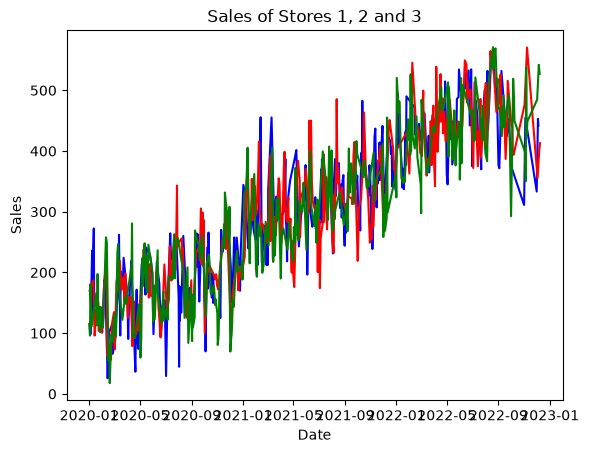

In [383]:
store1 = df[df["store_id"] == 1]
store2 = df[df["store_id"] == 2]
store3 = df[df["store_id"] == 3]

plt.plot(store1["date"], store1["sales"], color = 'blue')
plt.plot(store2["date"], store2["sales"], color = 'red')
plt.plot(store3["date"], store3["sales"], color = 'green')

plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Sales of Stores 1, 2 and 3")
plt.show()

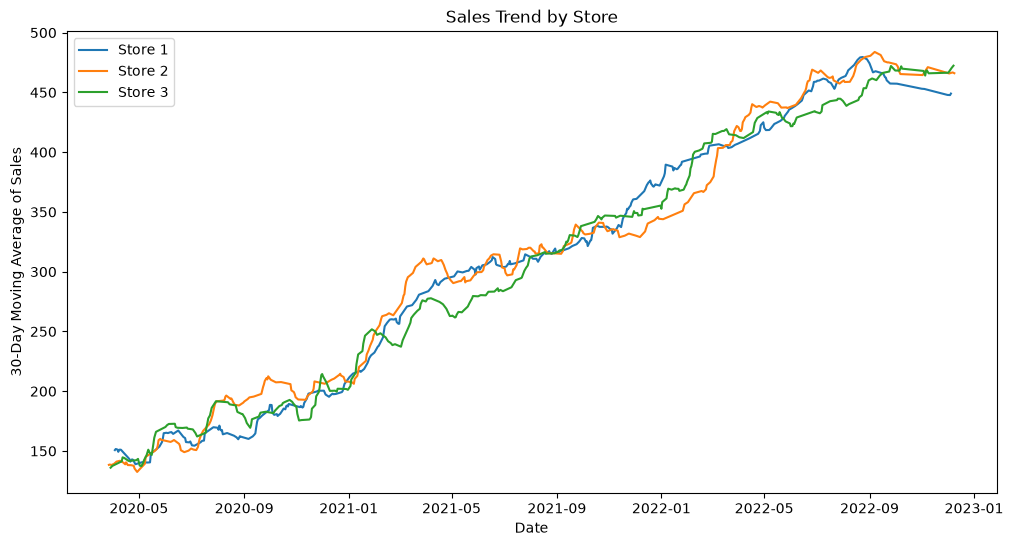

In [384]:
# with moving average

plt.figure(figsize=(12, 6))

for store, data in df.groupby("store_id"):
    data = data.sort_values("date")
    plt.plot(data["date"], data["sales"].rolling(window=30).mean(), label=f"Store {store}") #data["sales"] myyntisarake, .rolling(window=30) muodostaa 30 rivin "liukuvan ikkunan"

plt.xlabel("Date")
plt.ylabel("30-Day Moving Average of Sales")
plt.title("Sales Trend by Store")
plt.legend()
plt.show()

### Understanding Seasonality and Trends

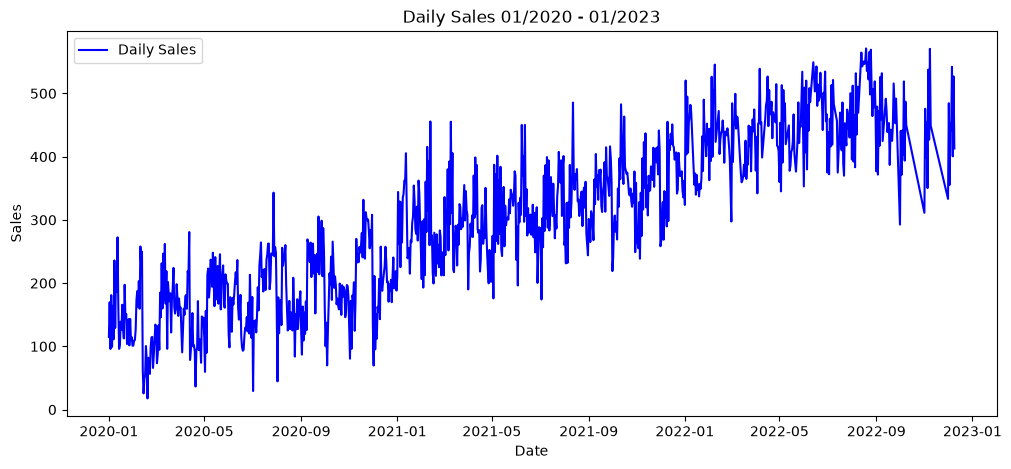

In [385]:
plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["sales"], label="Daily Sales", color='blue')
plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Daily Sales 01/2020 - 01/2023")
plt.legend()
plt.show()

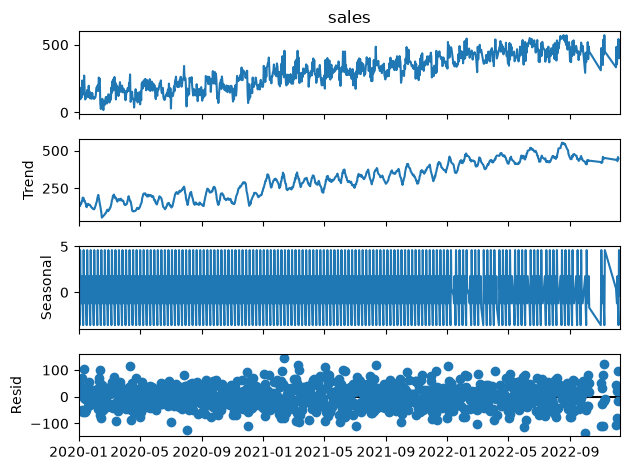

In [386]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(df.set_index("date")["sales"], model="additive", period=7)
decomposition.plot()
plt.show()

### Moving average for a daily sale (liukuva keskiarvo). 

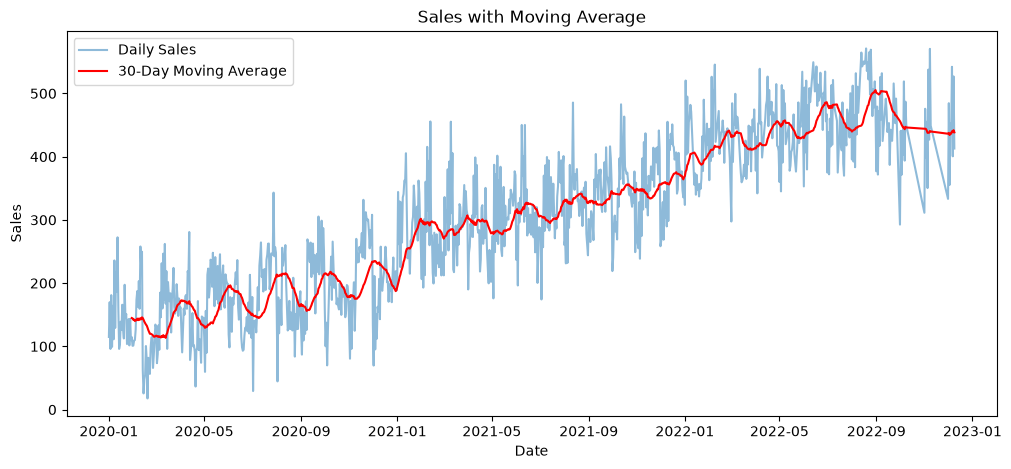

In [387]:
df["moving_avg"] = df["sales"].rolling(window=30).mean()

# Plot sales and moving average
plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["sales"], label="Daily Sales", alpha=0.5)
plt.plot(df["date"], df["moving_avg"], label="30-Day Moving Average", color='red')
plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Sales with Moving Average")
plt.legend()
plt.show()